<a href="https://colab.research.google.com/github/Ripazha05/Probabilitas-dan-Statistika-Projek-kelompok/blob/main/Analisis_Kelompok_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook Analisis Kelompok 9
**Analisis Statistika Deskriptif Pengeluaran Mahasiswa: Komponen Tempat Tinggal, Makanan, dan Total Pengeluaran**

Proyek Probabilitas dan Statistika, Teknik Informatika, Politeknik Caltex Riau (2026).

Notebook ini membaca lembar `Dataset` dari berkas Excel, membentuk `total_pengeluaran` (jumlah sembilan komponen, tanpa `tuition`), menghitung statistik deskriptif, dan membuat seluruh grafik pada laporan. Hasil statistik disimpan ke `hasil.json` dan grafik ke folder `grafik/`.

Kebutuhan: Python 3, pandas, numpy, matplotlib, openpyxl.

In [35]:
# Analisis statistika deskriptif pengeluaran mahasiswa - Kelompok 9
import json, os
import numpy as np, pandas as pd
import matplotlib
# Nonaktifkan backend non-interaktif 'Agg' agar diagram bisa muncul di notebook
# matplotlib.use("Agg")
import matplotlib.pyplot as plt

XLSX = "3TIE_09_StudentSpending.xlsx"   # letakkan berkas Excel di folder yang sama dengan notebook
OUT = "grafik"
JSON = "hasil.json"
os.makedirs(OUT, exist_ok=True)

In [36]:
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True})
C1, C2, C3 = "#00425B", "#C0392B", "#E08A00"   # biru PCR, merah, oranye

In [37]:
df = pd.read_excel(XLSX, sheet_name="student_spending")
komp = ["housing","food","transportation","books_supplies","entertainment",
        "personal_care","technology","health_wellness","miscellaneous"]
df["total_pengeluaran"] = df[komp].sum(axis=1)

res = {"shape": list(df.shape), "missing": int(df.isna().sum().sum()),
       "id_unik": bool(df["id"].is_unique), "duplikat": int(df.duplicated().sum())}

In [38]:
def ringkas(s):
    q1, q2, q3 = s.quantile([.25,.5,.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return dict(n=int(s.count()), mean=s.mean(), median=q2, modus=[float(x) for x in s.mode()],
                min=float(s.min()), max=float(s.max()), q1=q1, q3=q3, range=float(s.max()-s.min()),
                iqr=iqr, var=s.var(), sd=s.std(), se=s.std()/np.sqrt(s.count()),
                cv=s.std()/s.mean()*100, skew=s.skew(), kurt=s.kurt(),
                lo=lo, hi=hi, n_out_low=int((s<lo).sum()), n_out_high=int((s>hi).sum()))

res["stat"] = {v: ringkas(df[v]) for v in komp + ["total_pengeluaran"]}
tot_mean = df["total_pengeluaran"].mean()
res["share"] = {v: df[v].mean()/tot_mean*100 for v in komp}
res["sum_means_check"] = float(sum(df[v].mean() for v in komp))
fr = df["year_in_school"].value_counts().reindex(["Freshman","Sophomore","Junior","Senior"])
res["year"] = {k: int(v) for k, v in fr.items()}
res["year_pct"] = {k: float(v/len(df)*100) for k, v in fr.items()}
res["tuition_mean"] = float(df["tuition"].mean())
json.dump(res, open(JSON, "w"), indent=1, default=float)

def idn(x, d=2):
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def simpan(fig, nama):
    fig.savefig(f"{OUT}/{nama}.png", dpi=200, bbox_inches="tight")
    plt.show() # Tampilkan grafik di notebook sebelum ditutup
    plt.close(fig)

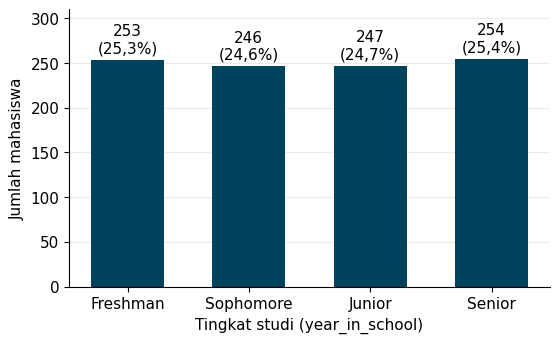

In [39]:
# G1 frekuensi year_in_school
fig, ax = plt.subplots(figsize=(6.2, 3.6))
b = ax.bar(fr.index, fr.values, color=C1, width=.6)
ax.bar_label(b, labels=[f"{v}\n({idn(v/len(df)*100,1)}%)" for v in fr.values], padding=3)
ax.set_ylim(0, fr.max()*1.22); ax.set_xlabel("Tingkat studi (year_in_school)"); ax.set_ylabel("Jumlah mahasiswa")
ax.grid(axis="x", visible=False); simpan(fig, "gambar_4_1_frekuensi_year_in_school")

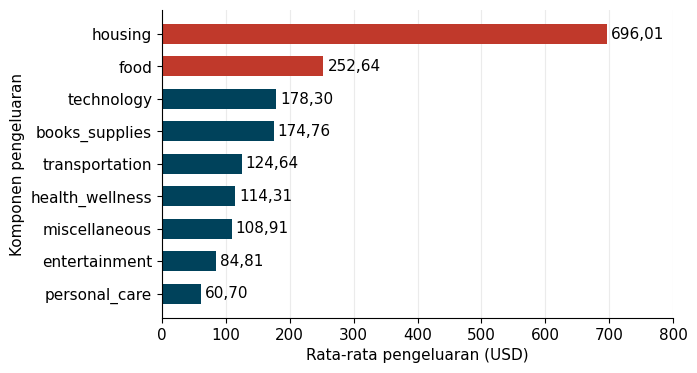

In [40]:
# G2 rata-rata komponen
m = df[komp].mean().sort_values()
fig, ax = plt.subplots(figsize=(6.6, 4.0))
cols = [C2 if k in ("housing","food") else C1 for k in m.index]
b = ax.barh(m.index, m.values, color=cols, height=.62)
ax.bar_label(b, labels=[idn(v) for v in m.values], padding=3)
ax.set_xlim(0, m.max()*1.15); ax.set_xlabel("Rata-rata pengeluaran (USD)"); ax.set_ylabel("Komponen pengeluaran")
ax.grid(axis="y", visible=False); simpan(fig, "gambar_4_2_rata_rata_komponen")

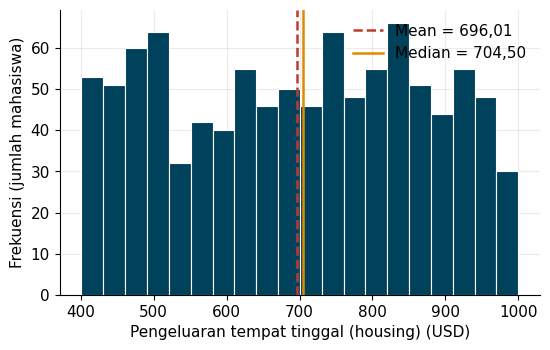

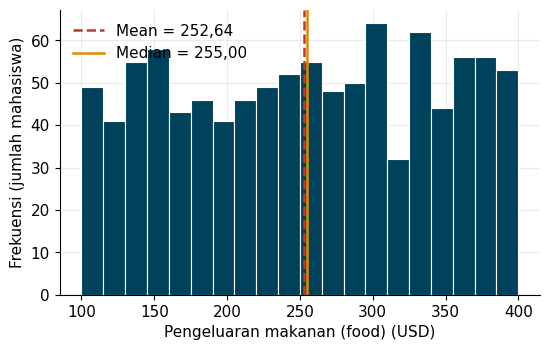

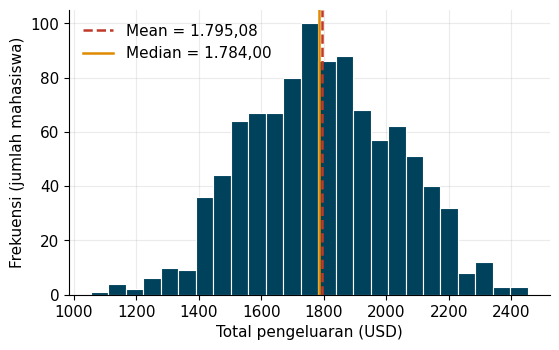

In [41]:
# G3-5 histogram
def hist(v, judul, nama, bins):
    s = df[v]; fig, ax = plt.subplots(figsize=(6.2, 3.7))
    ax.hist(s, bins=bins, color=C1, edgecolor="white", linewidth=.8)
    ax.axvline(s.mean(), color=C2, ls="--", lw=1.8, label=f"Mean = {idn(s.mean())}")
    ax.axvline(s.median(), color=C3, ls="-", lw=1.8, label=f"Median = {idn(s.median())}")
    ax.set_xlabel(judul + " (USD)"); ax.set_ylabel("Frekuensi (jumlah mahasiswa)")
    ax.legend(frameon=False); simpan(fig, nama)
hist("housing", "Pengeluaran tempat tinggal (housing)", "gambar_4_3_histogram_housing", 20)
hist("food", "Pengeluaran makanan (food)", "gambar_4_4_histogram_food", 20)
hist("total_pengeluaran", "Total pengeluaran", "gambar_4_5_histogram_total", 25)

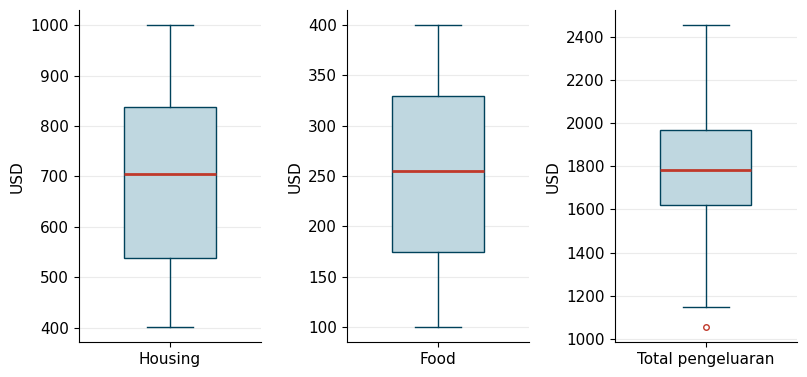

selesai [1000, 19] 0


In [42]:
# G6 boxplot
fig, axs = plt.subplots(1, 3, figsize=(8.2, 3.9))
for ax, v, t in zip(axs, ["housing","food","total_pengeluaran"], ["Housing","Food","Total pengeluaran"]):
    ax.boxplot(df[v], widths=.5, patch_artist=True, boxprops=dict(facecolor="#BFD7E0", color=C1),
               medianprops=dict(color=C2, lw=2), whiskerprops=dict(color=C1), capprops=dict(color=C1),
               flierprops=dict(marker="o", markersize=4, markeredgecolor=C2))
    ax.set_xticks([1], [t]); ax.set_ylabel("USD"); ax.grid(axis="x", visible=False)
fig.tight_layout(); simpan(fig, "gambar_4_6_boxplot")
print("selesai", res["shape"], res["missing"])

 Menampilkan Gambar 4.1...


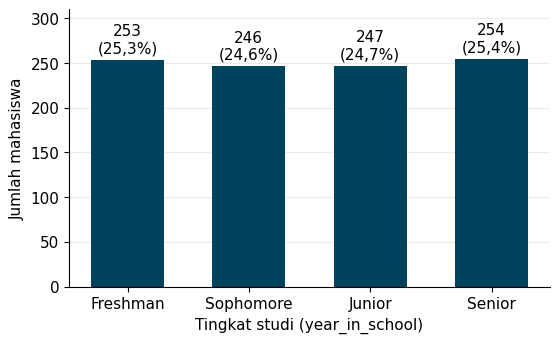


 Menampilkan Gambar 4.2...


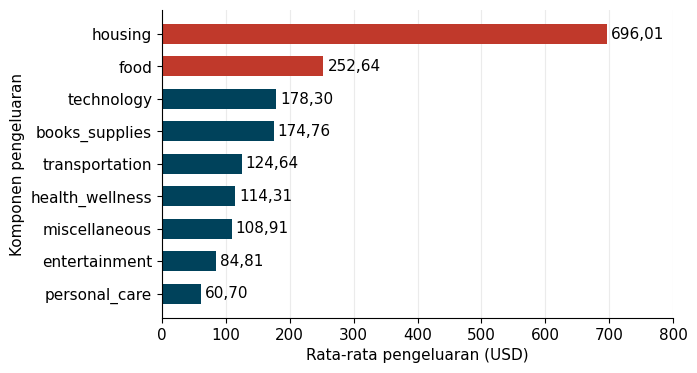


 Menampilkan Gambar 4.3, 4.4, 4.5...


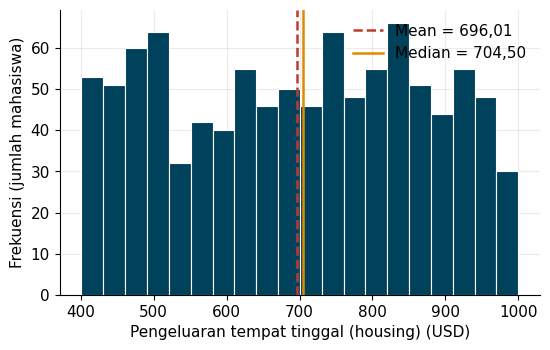

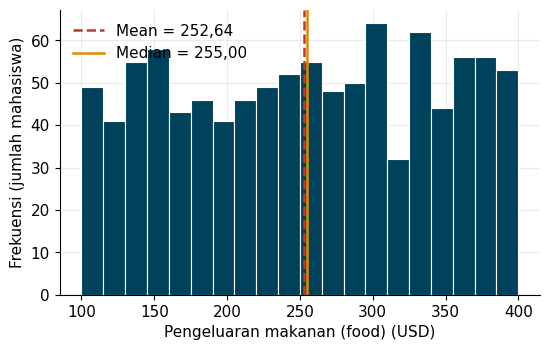

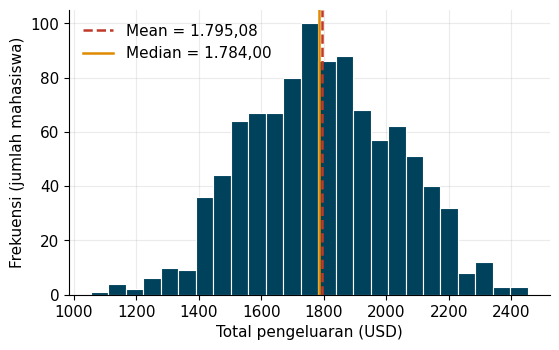


 Menampilkan Gambar 4.6...


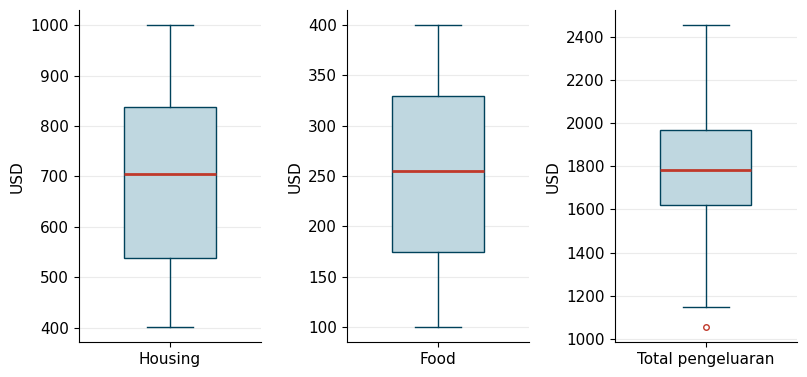

In [43]:
# === MENAMPILKAN SEMUA DIAGRAM SEKALIGUS ===

# Memastikan inline plotting aktif
%matplotlib inline

# 1. G1: Frekuensi year_in_school
print(" Menampilkan Gambar 4.1...")
fig1, ax1 = plt.subplots(figsize=(6.2, 3.6))
b1 = ax1.bar(fr.index, fr.values, color=C1, width=.6)
ax1.bar_label(b1, labels=[f"{v}\n({idn(v/len(df)*100,1)}%)" for v in fr.values], padding=3)
ax1.set_ylim(0, fr.max()*1.22)
ax1.set_xlabel("Tingkat studi (year_in_school)")
ax1.set_ylabel("Jumlah mahasiswa")
ax1.grid(axis="x", visible=False)
simpan(fig1, "gambar_4_1_frekuensi_year_in_school")

# 2. G2: Rata-rata Komponen
print("\n Menampilkan Gambar 4.2...")
m = df[komp].mean().sort_values()
fig2, ax2 = plt.subplots(figsize=(6.6, 4.0))
cols = [C2 if k in ("housing","food") else C1 for k in m.index]
b2 = ax2.barh(m.index, m.values, color=cols, height=.62)
ax2.bar_label(b2, labels=[idn(v) for v in m.values], padding=3)
ax2.set_xlim(0, m.max()*1.15)
ax2.set_xlabel("Rata-rata pengeluaran (USD)")
ax2.set_ylabel("Komponen pengeluaran")
ax2.grid(axis="y", visible=False)
simpan(fig2, "gambar_4_2_rata_rata_komponen")

# 3. G3-5: Histogram
print("\n Menampilkan Gambar 4.3, 4.4, 4.5...")
def tampilkan_dan_simpan_hist(v, judul, nama, bins):
    s = df[v]
    fig, ax = plt.subplots(figsize=(6.2, 3.7))
    ax.hist(s, bins=bins, color=C1, edgecolor="white", linewidth=.8)
    ax.axvline(s.mean(), color=C2, ls="--", lw=1.8, label=f"Mean = {idn(s.mean())}")
    ax.axvline(s.median(), color=C3, ls="-", lw=1.8, label=f"Median = {idn(s.median())}")
    ax.set_xlabel(judul + " (USD)")
    ax.set_ylabel("Frekuensi (jumlah mahasiswa)")
    ax.legend(frameon=False)
    simpan(fig, nama)

tampilkan_dan_simpan_hist("housing", "Pengeluaran tempat tinggal (housing)", "gambar_4_3_histogram_housing", 20)
tampilkan_dan_simpan_hist("food", "Pengeluaran makanan (food)", "gambar_4_4_histogram_food", 20)
tampilkan_dan_simpan_hist("total_pengeluaran", "Total pengeluaran", "gambar_4_5_histogram_total", 25)

# 4. G6: Boxplot
print("\n Menampilkan Gambar 4.6...")
fig3, axs3 = plt.subplots(1, 3, figsize=(8.2, 3.9))
for ax, v, t in zip(axs3, ["housing","food","total_pengeluaran"], ["Housing","Food","Total pengeluaran"]):
    ax.boxplot(df[v], widths=.5, patch_artist=True, boxprops=dict(facecolor="#BFD7E0", color=C1),
               medianprops=dict(color=C2, lw=2), whiskerprops=dict(color=C1), capprops=dict(color=C1),
               flierprops=dict(marker="o", markersize=4, markeredgecolor=C2))
    ax.set_xticks([1], [t])
    ax.set_ylabel("USD")
    ax.grid(axis="x", visible=False)
fig3.tight_layout()
simpan(fig3, "gambar_4_6_boxplot")

In [44]:
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.DataFrame(res['stat']).T[['n','mean','median','q1','q3','min','max','range','iqr','var','sd','se','cv','skew','kurt','n_out_low','n_out_high']]

,n,mean,median,q1,q3,min,max,range,iqr,var,sd,se,cv,skew,kurt,n_out_low,n_out_high
housing,1000,696.006,704.500,538.750,837.250,401.000,"1,000.000",599.000,298.500,"29,315.816",171.219,5.414,24.600,-0.052,-1.203,0,0
food,1000,252.642,255.000,175.000,330.000,100.000,400.000,300.000,155.000,"7,560.234",86.950,2.750,34.416,-0.048,-1.205,0,0
transportation,1000,124.637,123.000,88.000,162.250,50.000,200.000,150.000,74.250,"1,897.299",43.558,1.377,34.948,0.011,-1.189,0,0
books_supplies,1000,174.761,175.000,112.000,238.000,50.000,300.000,250.000,126.000,"5,242.414",72.405,2.290,41.431,0.013,-1.200,0,0
entertainment,1000,84.814,86.000,54.000,116.000,20.000,150.000,130.000,62.000,"1,441.755",37.970,1.201,44.769,-0.037,-1.165,0,0
personal_care,1000,60.699,62.000,41.000,80.000,20.000,100.000,80.000,39.000,524.319,22.898,0.724,37.724,-0.109,-1.118,0,0
technology,1000,178.304,178.000,114.000,241.000,50.000,300.000,250.000,127.000,"5,147.265",71.744,2.269,40.237,-0.016,-1.195,0,0
health_wellness,1000,114.310,115.000,73.000,158.000,30.000,200.000,170.000,85.000,"2,459.321",49.592,1.568,43.383,0.014,-1.179,0,0
miscellaneous,1000,108.910,110.000,63.750,153.000,20.000,200.000,180.000,89.250,"2,747.041",52.412,1.657,48.124,0.030,-1.195,0,0
total_pengeluaran,1000,"1,795.083","1,784.000","1,622.000","1,968.500","1,055.000","2,453.000","1,398.000",346.500,"56,881.243",238.498,7.542,13.286,-0.001,-0.350,1,0
